# T001 · 化合物数据获取（ChEMBL）

**说明：** 本教程（talktorial）属于 TeachOpenCADD 平台。该平台旨在教授领域相关技能，并提供可作为研究项目起点的流程模板。

作者：

- Svetlana Leng，CADD seminar 2017，Volkamer lab，Charité/FU Berlin
- Paula Junge，CADD seminar 2018，Volkamer lab，Charité/FU Berlin
- Dominique Sydow，2019–2020，[Volkamer lab, Charité](https://volkamerlab.org/)
- Andrea Volkamer，2020，[Volkamer lab, Charité](https://volkamerlab.org/)
- Yonghui Chen，2020，[Volkamer lab, Charité](https://volkamerlab.org/)


**TeachOpenCADD 教程 T001：** 本教程属于 TeachOpenCADD 流程的一部分。该流程在 [TeachOpenCADD 的首篇论文](https://jcheminf.biomedcentral.com/articles/10.1186/s13321-019-0351-x
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        )中介绍，包含 T001–T010 共十个教程。

## 本教程的目标

本笔记本将介绍 ChEMBL 数据库，以及如何从 ChEMBL 提取数据，例如针对指定靶点的化合物及其活性数据。此类数据集可用于多种化学信息学任务，例如相似性检索、聚类或机器学习。

本教程将检索针对某个靶点测试过的化合物，并筛选可用的生物活性数据。


### 理论部分内容

* ChEMBL 数据库
    * ChEMBL Web 服务
    * ChEMBL Web Resource Client（Web 资源客户端）
* 化合物活性指标
    * IC50 指标
    * pIC50 数值


### 实践部分内容
    
**目标：获取给定靶点的化合物及其生物活性数据**

* 连接 ChEMBL 数据库
* 获取靶点数据（以 EGFR 激酶为例）
    * 查询并下载靶点数据
    * 选择靶点的 ChEMBL ID
* 获取生物活性数据
    * 查询并下载靶点的生物活性数据
    * 预处理并筛选生物活性数据
* 获取化合物数据
    * 查询并下载化合物数据
    * 预处理并筛选化合物数据
* 输出生物活性与化合物数据
    * 合并生物活性数据和化合物数据，并添加 pIC50 数值
    * 绘制 pIC50 最高的分子
    * 将生物活性数据固定到 ChEMBL 27 版本
    * 写出结果文件


### 参考资料

* ChEMBL 生物活性数据库：[Gaulton *等*, <i>Nucleic Acids Res.</i> (2017), 45(Database issue), D945–D954](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5210557
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        /)
* ChEMBL Web 服务：[Davies *等*, <i>Nucleic Acids Res.</i> (2015), <b>43</b>, 612–620](https://academic.oup.com/nar/article/43/W1/W612/2467881)
* [ChEMBL 网页界面](https://www.ebi.ac.uk/chembl/)
* GitHub 上的 [ChEMBL Web Resource Client](https://github.com/chembl/chembl_webresource_client)
* EBI RDF 平台：[Jupp *等*, <i>Bioinformatics</i> (2014), 30(9), 1338–1339](https://www.ncbi.nlm.nih.gov/pubmed/24413672)
* 半数抑制浓度简介：[(p)IC50](https://en.wikipedia.org/wiki/IC50)
* [UniProt 网站](https://www.uniprot.org/)


In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install teachopencadd --no-deps -q
    !teachopencadd -d 1
    %pip uninstall teachopencadd -y -q
    %pip install -qr requirements.txt

## 理论

>“ChEMBL 是一个经过人工整理的、包含具有类药性质的生物活性分子的数据库。它整合化学、生物活性和基因组数据，帮助将基因组信息转化为有效的新药。”（[ChEMBL 网站](https://www.ebi.ac.uk/chembl/)）

* 大型生物活性数据库
* **数据规模（截至 2020 年 9 月，ChEMBL 27）：**
    * 超过 190 万种不同化合物
    * 超过 1600 万条活性数值
    * 测定实验映射到约 13,000 个靶点
* **数据来源**包括科学文献、PubChem 生物测定、被忽视疾病药物倡议（DNDi）、BindingDB 数据库等
* ChEMBL 数据可通过[网页界面](https://www.ebi.ac.uk/chembl/)、[EBI-RDF 平台](https://www.ncbi.nlm.nih.gov/pubmed/24413672)以及 [ChEMBL Web Resource Client](https://github.com/chembl/chembl_webresource_client)访问


#### ChEMBL Web 服务

* RESTful Web 服务
* ChEMBL Web 服务 2.x 资源结构：

<!---
![ChEMBL web service schema](images/chembl_webservices_schema_diagram.jpg)
--->
![ChEMBL web service schema](images/chembl_webservices_schema_diagram.jpg)

*图 1：* [ChEMBL Web 服务结构示意图](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4489243
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        /figure/F2/)。椭圆表示 ChEMBL Web 服务资源，两项资源之间的连线表示它们共享某个属性。箭头方向表示某类资源的主要信息所在位置。虚线表示资源间的关系具有不同的行为。例如，`Image` 资源提供 `Molecule` 的图形表示。
图及说明引自：[<i>Nucleic Acids Res.</i> (2015), <b>43</b>, 612–620](https://academic.oup.com/nar/article/43/W1/W612/2467881)。


#### ChEMBL Web Resource Client

* 用于访问 ChEMBL 数据的 Python 客户端库
* 负责处理 HTTPS 协议交互
* 采用惰性求值，减少网络请求次数


### 化合物活性指标

#### IC50 指标

* [半数抑制浓度](https://en.wikipedia.org/wiki/IC50)
* 表示使某一生物过程受到 50% 抑制所需的药物或其他物质浓度

![Wiki_Example_IC50_curve_demonstrating_visually_how_IC50_is_derived](images/Wiki_Example_IC50_curve_demonstrating_visually_how_IC50_is_derived.png)

*图 2：* IC50 的图示推导过程：（i）以抑制率为 y 轴、浓度的对数为 x 轴绘制数据；（ii）确定最大和最小抑制率；（iii）曲线达到 50% 抑制率时对应的浓度即为 IC50。图片 [“Example IC50 curve demonstrating visually how IC50 is derived”](https://en.wikipedia.org/wiki/IC50#/media/File:Example_IC50_curve_demonstrating_visually_how_IC50_is_derived.png)由 JesseAlanGordon 创作，采用 [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/) 许可。


#### pIC50 数值

* IC50 数值的范围可能很大，且单位各异（M、nM 等）；为便于比较，常使用 pIC50。
* pIC50 是 IC50 换算为摩尔浓度后的负对数：
    pIC₅₀ = −log₁₀(IC₅₀)，其中 IC₅₀ 的单位为 M。
* pIC50 越高，表示该药物的效力呈指数级增强。
* 换算公式可根据 IC50 的单位调整。例如，若单位为 nM：pIC₅₀ = 9 − log₁₀(IC₅₀[nM])。

其他活性指标：

除 IC50 和 pIC50 外，常见的生物活性指标还包括平衡常数 [K<sub>I</sub>](https://en.wikipedia.org/wiki/Equilibrium_constant) 和半数有效浓度 [EC50](https://en.wikipedia.org/wiki/EC50)。


## 实践

接下来，我们将下载针对目标——**表皮生长因子受体**（[**EGFR**](https://www.uniprot.org/uniprot/P00533)）激酶——测试过的所有分子。

### 选择数据来源

默认使用随课附带的 ChEMBL 27 活性数据和化合物结构快照，可以直接从头运行。想练习实时查询，把下面的 `USE_LIVE_CHEMBL` 改成 `True`，再重新运行整本 Notebook。在线模式会访问公开的 ChEMBL REST API，返回的记录数会随数据库版本变化。

导入用于整理数据、绘图、显示分子结构和访问 API 的 Python 库。

In [2]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
from rdkit.Chem import PandasTools
import requests
from urllib.parse import urljoin
from tqdm.auto import tqdm

In [3]:
HERE = Path(_dh[-1])
DATA = HERE / "data"

联网时用 GET 请求读取资源。`limit` 指定每页最多返回的记录数。若响应中的 `page_meta.next` 有值，就继续请求下一页。

In [8]:
CHEMBL_API = "https://www.ebi.ac.uk/chembl/api/data/"
USE_LIVE_CHEMBL = False


def get_chembl_records(resource, params):
    """下载并合并 ChEMBL API 各页的记录。"""
    url = urljoin(CHEMBL_API, f"{resource}.json")
    collection = "activities" if resource == "activity" else f"{resource}s"
    records = []
    with requests.Session() as session:
        while url:
            response = session.get(url, params=params, timeout=60)
            response.raise_for_status()
            page = response.json()
            records.extend(page[collection])
            next_page = page["page_meta"]["next"]
            url = urljoin(url, next_page) if next_page else None
            params = None
    return records

In [9]:
print("数据来源：ChEMBL 实时查询" if USE_LIVE_CHEMBL else "数据来源：本地教学快照（ChEMBL 27）")

数据来源：本地教学快照（ChEMBL 27）


### 获取靶点数据（EGFR 激酶）

* 从 [UniProt 网站](https://www.uniprot.org/)获取目标靶点（EGFR 激酶）的 UniProt ID：[P00533](http://www.uniprot.org/uniprot/P00533)
* 使用 UniProt ID 查询靶点信息

如果要研究其他靶点，请在此处换用相应的 UniProt ID。


In [10]:
uniprot_id = "P00533"

#### 从 ChEMBL 查询靶点数据

In [11]:
if USE_LIVE_CHEMBL:
    targets = get_chembl_records(
        "target",
        {
            "target_components__accession": uniprot_id,
            "only": "target_chembl_id,organism,pref_name,target_type",
            "limit": 1000,
        },
    )
else:
    targets = [
        {
            "target_chembl_id": "CHEMBL203",
            "organism": "Homo sapiens",
            "pref_name": "Epidermal growth factor receptor",
            "target_type": "SINGLE PROTEIN",
        }
    ]
print(f"靶点记录数：{len(targets)}")

靶点记录数：1


#### 检查靶点查询结果

`targets` 是由靶点记录组成的列表。单条记录以字典存储，字段包括靶点名、物种、靶点类型和 ChEMBL ID。下面把记录转换成表格，便于核对。

In [14]:
targets = pd.DataFrame.from_records(targets)
targets

,target_chembl_id,organism,pref_name,target_type
0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,SINGLE PROTEIN


#### 选择靶点（target ChEMBL ID）

检查返回的条目后，我们选择第一条作为目标：

`CHEMBL203`：单一蛋白，代表人表皮生长因子受体（EGFR，也称 erbB1）。


In [15]:
target = targets.iloc[0]
target

target_chembl_id                           CHEMBL203
organism                                Homo sapiens
pref_name           Epidermal growth factor receptor
target_type                           SINGLE PROTEIN
Name: 0, dtype: str

保存选定的 ChEMBL ID。

In [16]:
chembl_id = target.target_chembl_id
print(f"The target ChEMBL ID is {chembl_id}")
# NBVAL_CHECK_OUTPUT

The target ChEMBL ID is CHEMBL203


### 获取生物活性数据

现在，我们来查询目标靶点的生物活性数据。

#### 查询目标靶点的生物活性数据

此步骤将获取生物活性数据，并筛选出符合以下条件的记录：

* 靶点为人类蛋白；
* 生物活性类型为 IC50；
* 测量关系为精确值（关系符 `=`）；
* 测定类型为结合实验（assay type `B`）。


In [17]:
if USE_LIVE_CHEMBL:
    bioactivities = get_chembl_records(
        "activity",
        {
            "target_chembl_id": chembl_id,
            "type": "IC50",
            "relation": "=",
            "assay_type": "B",
            "only": (
                "activity_id,assay_chembl_id,assay_description,assay_type,"
                "molecule_chembl_id,type,standard_units,relation,standard_value,"
                "target_chembl_id,target_organism,units,value"
            ),
            "limit": 1000,
        },
    )
else:
    bioactivities = pd.read_csv(
        DATA / "EGFR_bioactivities_CHEMBL27.csv.zip", index_col=0
    ).to_dict("records")

print(f"活性记录数：{len(bioactivities):,}")

活性记录数：7,178


生物活性数据集的每条记录都包含以下信息：

In [18]:
print(f"Length and type of first element: {len(bioactivities[0])}, {type(bioactivities[0])}")
bioactivities[0]

Length and type of first element: 13, <class 'dict'>


{'activity_id': 32260,
 'assay_chembl_id': 'CHEMBL674637',
 'assay_description': 'Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor kinase',
 'assay_type': 'B',
 'molecule_chembl_id': 'CHEMBL68920',
 'relation': '=',
 'standard_units': 'nM',
 'standard_value': 41.0,
 'target_chembl_id': 'CHEMBL203',
 'target_organism': 'Homo sapiens',
 'type': 'IC50',
 'units': 'uM',
 'value': 0.041}

#### 下载 ChEMBL 生物活性数据

将活性记录列表转换为 `pandas` 的 `DataFrame`。实时下载遇到错误或耗时较长时，可以把 `USE_LIVE_CHEMBL` 改回 `False`，再从头运行，继续用随课数据练习。

In [19]:
bioactivities_df = pd.DataFrame.from_dict(bioactivities)
print(f"DataFrame shape: {bioactivities_df.shape}")
bioactivities_df.head()

DataFrame shape: (7178, 13)


/tmp/ipykernel_337550/2795309231.py:1: Pandas4Warning: Passing a list to DataFrame.from_dict is deprecated. Use the DataFrame constructor instead.
  bioactivities_df = pd.DataFrame.from_dict(bioactivities)


,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type,units,value
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50,uM,0.041
1,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50,uM,0.041
2,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50,uM,0.170
3,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50,uM,9.300
4,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50,uM,500.000


表中有原始单位和数值（`units`、`value`），也有 ChEMBL 标准化后的单位和数值（`standard_units`、`standard_value`）。后续计算采用标准化结果，这里删除原始两列。

In [20]:
bioactivities_df["units"].unique()

<StringArray>
[         'uM',          'nM',          'pM',           'M',     '10'3 uM',
  '10'1 ug/ml',     'ug ml-1', '10'-1microM',     '10'1 uM', '10'-1 ug/ml',
 '10'-2 ug/ml',     '10'2 uM', '10'-3 ug/ml', '10'-2microM',         '/uM',
   '10'-6g/ml',          'mM',      'umol/L',      'nmol/L',     '10'-10M']
Length: 20, dtype: str

In [21]:
bioactivities_df.drop(["units", "value"], axis=1, inplace=True)
bioactivities_df.head()

/tmp/ipykernel_337550/1542712408.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bioactivities_df.drop(["units", "value"], axis=1, inplace=True)


,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
1,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
2,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50
3,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50
4,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50


#### 预处理并筛选生物活性数据

1. 将 `standard_value` 的数据类型从 `object` 转为 `float`
2. 删除缺失值
3. 仅保留 `standard_units == nM` 的记录
4. 删除重复化合物
5. 重置 `DataFrame` 索引
6. 重命名列


**1. 将 `standard_value` 的数据类型从 `object` 转为 `float`**

`standard_value` 字段保存标准化后的数值（此处为 IC50）。为便于后续计算，需要将其转换为浮点数。


In [16]:
bioactivities_df.dtypes

activity_id             int64
assay_chembl_id           str
assay_description         str
assay_type                str
molecule_chembl_id        str
relation                  str
standard_units            str
standard_value        float64
target_chembl_id          str
target_organism           str
type                      str
dtype: object

In [17]:
bioactivities_df = bioactivities_df.astype({"standard_value": "float64"})
bioactivities_df.dtypes

activity_id             int64
assay_chembl_id           str
assay_description         str
assay_type                str
molecule_chembl_id        str
relation                  str
standard_units            str
standard_value        float64
target_chembl_id          str
target_organism           str
type                      str
dtype: object

**2. 删除缺失值**

使用参数 `inplace=True`，可直接在当前 `DataFrame` 中删除相应记录。

In [18]:
bioactivities_df.dropna(axis=0, how="any", inplace=True)
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (7177, 11)


/tmp/ipykernel_277383/3215596380.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bioactivities_df.dropna(axis=0, how="any", inplace=True)


**3. 仅保留 `standard_unit == nM` 的记录**

我们只保留单位为 nM 的生物活性记录，因此删除其他单位的记录。

In [19]:
print(f"Units in downloaded data: {bioactivities_df['standard_units'].unique()}")
print(f"Number of non-nM entries:\
    {bioactivities_df[bioactivities_df['standard_units'] != 'nM'].shape[0]}")

Units in downloaded data: <StringArray>
['nM', 'ug.mL-1', '/uM']
Length: 3, dtype: str
Number of non-nM entries:    64


In [20]:
bioactivities_df = bioactivities_df[bioactivities_df["standard_units"] == "nM"]
print(f"Units after filtering: {bioactivities_df['standard_units'].unique()}")

Units after filtering: <StringArray>
['nM']
Length: 1, dtype: str


In [21]:
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (7113, 11)


**4. 删除重复化合物**

有时同一化合物（`molecule_chembl_id`）会被测定多次；此处只保留第一次记录。

也可以采用其他处理方式，例如保留活性值最佳的一条，或对该化合物的所有测定结果取平均值。


In [22]:
bioactivities_df.drop_duplicates("molecule_chembl_id", keep="first", inplace=True)
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (5451, 11)


/tmp/ipykernel_277383/2945230611.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bioactivities_df.drop_duplicates("molecule_chembl_id", keep="first", inplace=True)


**5. 重置 `DataFrame` 索引**

删除了部分行后，为便于之后按索引迭代，将索引重置为连续编号。

In [23]:
bioactivities_df.reset_index(drop=True, inplace=True)
bioactivities_df.head()

/tmp/ipykernel_277383/3204015299.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bioactivities_df.reset_index(drop=True, inplace=True)


,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
1,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50
2,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50
3,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50
4,32772,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL66879,=,nM,3000000.0,CHEMBL203,Homo sapiens,IC50


**6. 重命名列**

In [24]:
bioactivities_df.rename(
    columns={"standard_value": "IC50", "standard_units": "units"}, inplace=True
)
bioactivities_df.head()

/tmp/ipykernel_277383/3850770068.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bioactivities_df.rename(


,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,units,IC50,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
1,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50
2,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50
3,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50
4,32772,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL66879,=,nM,3000000.0,CHEMBL203,Homo sapiens,IC50


In [25]:
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (5451, 11)


现在每个保留的分子 ID 对应一条以 nM 为单位的 IC50 记录，可以用这些 ID 去取分子结构。实时查询和本地教学快照得到的记录数可能不同。

### 获取化合物数据

现在，我们有一个 `DataFrame`，其中包含所有针对 EGFR 测试过的分子及其相应的生物活性测量值。

接下来，获取与相应生物活性数据关联的 ChEMBL ID 所对应的分子结构。


#### 获取与活性记录对应的化合物结构

联机时按 ChEMBL 化合物 ID 分批查询，避免单个 URL 过长。离线时从随课数据读取化合物 ID 和 canonical SMILES，再转换成后续代码使用的记录结构。

In [26]:
compound_ids = bioactivities_df["molecule_chembl_id"].dropna().tolist()
if USE_LIVE_CHEMBL:
    compounds = []
    for start in tqdm(range(0, len(compound_ids), 150)):
        compounds.extend(
            get_chembl_records(
                "molecule",
                {
                    "molecule_chembl_id__in": ",".join(compound_ids[start : start + 150]),
                    "only": "molecule_chembl_id,molecule_structures",
                    "limit": 1000,
                },
            )
        )
else:
    structures = pd.read_csv(
        DATA / "EGFR_compounds_ea055ef.csv",
        usecols=["molecule_chembl_id", "smiles"],
    )
    compounds = [
        {
            "molecule_chembl_id": molecule_id,
            "molecule_structures": {"canonical_smiles": smiles},
        }
        for molecule_id, smiles in structures.itertuples(index=False, name=None)
    ]

#### 下载 ChEMBL 化合物数据

同样，我们要将 `QuerySet` 对象导出为 `pandas.DataFrame`。数据量较大，**此步骤可能需要一些时间。**因此，先通过 `tqdm` 获取记录列表，以显示进度条和预计剩余时间，再将化合物列表传入 DataFrame。


In [27]:
print(f"获得 {len(compounds):,} 条化合物结构记录")

获得 5,568 条化合物结构记录


In [28]:
compounds_df = pd.DataFrame.from_records(
    compounds,
)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5568, 2)


In [29]:
compounds_df.head()

,molecule_chembl_id,molecule_structures
0,CHEMBL63786,{'canonical_smiles': 'Brc1cccc(Nc2ncnc3cc4cccc...
1,CHEMBL35820,{'canonical_smiles': 'CCOc1cc2ncnc(Nc3cccc(Br)...
2,CHEMBL53711,{'canonical_smiles': 'CN(C)c1cc2c(Nc3cccc(Br)c...
3,CHEMBL66031,{'canonical_smiles': 'Brc1cccc(Nc2ncnc3cc4[nH]...
4,CHEMBL53753,{'canonical_smiles': 'CNc1cc2c(Nc3cccc(Br)c3)n...


#### 预处理并筛选化合物数据

1. 删除结构信息缺失的记录
2. 按 `molecule_chembl_id` 删除重复化合物
3. 获取具有 canonical SMILES 的分子


**1. 删除分子结构条目缺失的记录**

In [30]:
compounds_df.dropna(axis=0, how="any", inplace=True)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5568, 2)


/tmp/ipykernel_277383/3679739470.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  compounds_df.dropna(axis=0, how="any", inplace=True)


**2. 删除重复化合物**

In [31]:
compounds_df.drop_duplicates("molecule_chembl_id", keep="first", inplace=True)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5568, 2)


/tmp/ipykernel_277383/1408261796.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  compounds_df.drop_duplicates("molecule_chembl_id", keep="first", inplace=True)


**3. 获取具有 canonical SMILES 的分子**

目前有多种不同的分子结构表示形式。此处仅保留 canonical SMILES。

In [32]:
compounds_df.iloc[0].molecule_structures.keys()

dict_keys(['canonical_smiles'])

In [33]:
canonical_smiles = []

for i, compounds in compounds_df.iterrows():
    try:
        canonical_smiles.append(compounds["molecule_structures"]["canonical_smiles"])
    except KeyError:
        canonical_smiles.append(None)

compounds_df["smiles"] = canonical_smiles
compounds_df.drop("molecule_structures", axis=1, inplace=True)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5568, 2)


/tmp/ipykernel_277383/3094730047.py:10: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  compounds_df.drop("molecule_structures", axis=1, inplace=True)


合理性检查：删除所有没有 canonical SMILES 字符串的分子。

In [34]:
compounds_df.dropna(axis=0, how="any", inplace=True)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5568, 2)


/tmp/ipykernel_277383/3679739470.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  compounds_df.dropna(axis=0, how="any", inplace=True)


### 输出（生物活性与化合物）数据
**化合物和生物活性数据概览**

In [35]:
print(f"Bioactivities filtered: {bioactivities_df.shape[0]}")
bioactivities_df.columns

Bioactivities filtered: 5451


Index(['activity_id', 'assay_chembl_id', 'assay_description', 'assay_type',
       'molecule_chembl_id', 'relation', 'units', 'IC50', 'target_chembl_id',
       'target_organism', 'type'],
      dtype='str')

In [36]:
print(f"Compounds filtered: {compounds_df.shape[0]}")
compounds_df.columns

Compounds filtered: 5568


Index(['molecule_chembl_id', 'smiles'], dtype='str')

#### 合并两个数据集

根据化合物的 ChEMBL ID（`molecule_chembl_id`），将 `bioactivities_df` 和 `compounds_df` 中需要的值合并到 `output_df`，保留以下列：

* ChEMBL ID：`molecule_chembl_id`
* SMILES：`smiles`
* 单位：`units`
* IC50：`IC50`


In [37]:
# Merge DataFrames
output_df = pd.merge(
    bioactivities_df[["molecule_chembl_id", "IC50", "units"]],
    compounds_df,
    on="molecule_chembl_id",
)

# Reset row indices
output_df.reset_index(drop=True, inplace=True)

print(f"Dataset with {output_df.shape[0]} entries.")

Dataset with 5444 entries.


/tmp/ipykernel_277383/2711405738.py:9: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  output_df.reset_index(drop=True, inplace=True)


In [38]:
output_df.dtypes

molecule_chembl_id        str
IC50                  float64
units                     str
smiles                    str
dtype: object

In [39]:
output_df.head(10)

,molecule_chembl_id,IC50,units,smiles
0,CHEMBL68920,41.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...
1,CHEMBL69960,170.0,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...
2,CHEMBL137635,9300.0,nM,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12
3,CHEMBL306988,500000.0,nM,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1
4,CHEMBL66879,3000000.0,nM,O=C(O)/C=C/c1ccc(O)cc1
5,CHEMBL77085,96000.0,nM,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-]
6,CHEMBL443268,5310.0,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)N(C)c2...
7,CHEMBL76979,264000.0,nM,COc1cc(/C=C(\C#N)C(=O)O)cc(OC)c1O
8,CHEMBL76589,125.0,nM,N#CC(C#N)=C(N)/C(C#N)=C/c1ccc(O)cc1
9,CHEMBL76904,35000.0,nM,N#CC(C#N)=Cc1ccc(O)c(O)c1


#### 添加 pIC50 数值

如上所示，IC50 数值范围跨度较大，不便于直观比较，因此我们将其转换为 pIC50。

In [40]:
def convert_ic50_to_pic50(IC50_value):
    pIC50_value = 9 - math.log10(IC50_value)
    return pIC50_value

In [41]:
# Apply conversion to each row of the compounds DataFrame
output_df["pIC50"] = output_df.apply(lambda x: convert_ic50_to_pic50(x.IC50), axis=1)

In [42]:
output_df.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL68920,41.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,7.387216
1,CHEMBL69960,170.0,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,6.769551
2,CHEMBL137635,9300.0,nM,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,5.031517
3,CHEMBL306988,500000.0,nM,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,3.301030
4,CHEMBL66879,3000000.0,nM,O=C(O)/C=C/c1ccc(O)cc1,2.522879


#### 绘制化合物数据

先查看收集到的数据集。

首先，绘制 pIC50 数值分布：

array([[<Axes: title={'center': 'pIC50'}>]], dtype=object)

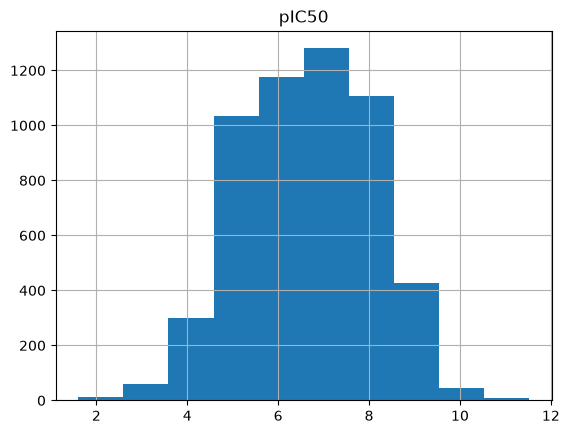

In [43]:
output_df.hist(column="pIC50")

接下来的步骤会在 `DataFrame` 中添加一列 RDKit 分子对象，并查看 pIC50 数值最高的分子结构。

In [44]:
# Add molecule column
PandasTools.AddMoleculeColumnToFrame(output_df, smilesCol="smiles")

In [45]:
# Sort molecules by pIC50
output_df.sort_values(by="pIC50", ascending=False, inplace=True)

# Reset index
output_df.reset_index(drop=True, inplace=True)

/tmp/ipykernel_277383/3086723367.py:2: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  output_df.sort_values(by="pIC50", ascending=False, inplace=True)
/tmp/ipykernel_277383/3086723367.py:5: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  output_df.reset_index(drop=True, inplace=True)


显示活性最高的三个分子，即 pIC50 数值最高的分子。

In [46]:
output_df.drop("smiles", axis=1).head(3)

,molecule_chembl_id,IC50,units,pIC50,ROMol
0,CHEMBL63786,0.003,nM,11.522879,<rdkit.Chem.rdchem.Mol object at 0x7b77fe40f0d0>
1,CHEMBL53711,0.006,nM,11.221849,<rdkit.Chem.rdchem.Mol object at 0x7b77fe406880>
2,CHEMBL35820,0.006,nM,11.221849,<rdkit.Chem.rdchem.Mol object at 0x7b77fe3f9a10>


In [47]:
# Prepare saving the dataset: Drop the ROMol column
output_df = output_df.drop("ROMol", axis=1)
print(f"DataFrame shape: {output_df.shape}")

DataFrame shape: (5444, 5)


#### 将输出数据固定到 ChEMBL 27 版本

这是一个技术性步骤。通常，我们会继续使用刚刚生成的最新数据集。

不过，在 TeachOpenCADD 平台中，我们倾向于将数据集固定到特定的 ChEMBL 版本（即 [ChEMBL 27](http://doi.org/10.6019/CHEMBL.database.27
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        )），这样本教程以及 CADD 流程中后续的教程就不会随数据库更新而改变，便于维护。


<div class="alert alert-block alert-info">

<b>注意：</b>如果你希望使用最新数据运行本笔记本，或希望研究其他靶点，请注释掉下面的单元格。

</div>


In [48]:
# Disable this cell to unfreeze the dataset
output_df = pd.read_csv(
    DATA / "EGFR_compounds_ea055ef.csv", index_col=0, float_precision="round_trip"
)
output_df.head()

/tmp/ipykernel_277383/1202589661.py:2: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  output_df = pd.read_csv(


,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL63786,0.003,nM,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,11.522879
1,CHEMBL35820,0.006,nM,CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC,11.221849
2,CHEMBL53711,0.006,nM,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.221849
3,CHEMBL66031,0.008,nM,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,11.096910
4,CHEMBL53753,0.008,nM,CNc1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.096910


In [49]:
print(f"DataFrame shape: {output_df.shape}")
# NBVAL_CHECK_OUTPUT

DataFrame shape: (5568, 5)


#### 将输出数据写入文件

后续教程将使用这个生物活性与化合物数据集，因此我们将数据保存为 `csv` 文件。
保存时建议删除分子对象列，因为该列仅包含分子图像。


In [50]:
output_df.to_csv(DATA / "EGFR_compounds.csv")
output_df.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL63786,0.003,nM,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,11.522879
1,CHEMBL35820,0.006,nM,CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC,11.221849
2,CHEMBL53711,0.006,nM,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.221849
3,CHEMBL66031,0.008,nM,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,11.096910
4,CHEMBL53753,0.008,nM,CNc1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.096910


In [51]:
print(f"DataFrame shape: {output_df.shape}")
# NBVAL_CHECK_OUTPUT

DataFrame shape: (5568, 5)


## 讨论

在本教程中，我们从 ChEMBL 数据库中收集了目标靶点的生物活性数据，并筛选出具有实测 IC50 生物活性值的分子。

请注意，ChEMBL 数据来自多种来源。不同实验室、不同研究者在世界各地生成了化合物数据。因此，基于这些数据集进行预测时需要谨慎。解释结果并判断预测可信度时，应充分考虑数据来源，以及不同测定实验在数据生成上的一致性。

在接下来的教程中，我们将根据 Lipinski 五规则和不希望出现的子结构进一步筛选所获数据。分子数据清洗也是重要步骤。由于目前的教程尚未介绍这部分内容，我们推荐使用 [Standardiser 库](https://github.com/flatkinson/standardiser)或 [MolVS](https://molvs.readthedocs.io/en/latest/) 等工具。


## 测验

* 本教程从 ChEMBL 下载了分子及其生物活性数据。ChEMBL 数据库还可用于哪些研究？
* IC50 和 EC50 有何区别？
* 从 ChEMBL 提取的数据可用于哪些任务？


## 面向 CADD 博士生的延伸练习

本教程在生物活性数据预处理中，对每个化合物只保留第一条 IC50 记录。请在去重前保留测定信息，设计一个更稳健的化合物活性汇总与排序方案：

1. 将 nM 单位的 IC50 转为 pIC50，并对每个化合物汇总多次测定（例如报告中位数、测定次数和离散程度）。
2. 按 `assay_chembl_id` 或测定描述分层，比较不同实验间的活性差异及化合物排序的一致性。
3. 说明测定条件和数据来源的异质性如何影响活性标签、虚拟筛选排序与模型训练；列出你会在报告中保留的质量控制信息。

讨论时请区分实验测得的 IC50 与靶点结合亲和力或体内药效，不要将它们直接等同。

## 中文版本与来源说明

本文件为 TeachOpenCADD T001 的中文译本，并补充了上述练习。中文版提供本地快照模式，联网实操改用 ChEMBL REST API 的 GET 查询。原作者信息保留在笔记本开头。上游来源：[TeachOpenCADD T001（commit `834b9ff59af69e8ba8d42aae23e92c15eb734ef0`）](https://github.com/volkamerlab/teachopencadd/blob/834b9ff59af69e8ba8d42aae23e92c15eb734ef0/teachopencadd/talktorials/T001_query_chembl/talktorial.ipynb)。上游项目采用 [Creative Commons Attribution 4.0 International（CC BY 4.0）](https://creativecommons.org/licenses/by/4.0/) 许可；图 2 等第三方素材仍按原图注所列许可。